**Домашнее задание №1: EDA по кредитному риску**

**1. Постановка задачи**

**1.1 Бизнес-постановка**

Банк ежегодно рассматривает десятки тысяч заявок на потребительский кредит. Ручная проверка каждой заявки занимает много времени, а ошибки приводят к двум типам потерь:

•	Пропуск «плохого» клиента (одобрение кредита тому, кто уйдёт в просрочку) → прямые финансовые потери из-за невозврата.

•	Отказ «хорошему» клиенту (ложное отклонение платёжеспособного заёмщика) → упущенная прибыль и недовольство клиента.

**Бизнес-цель:**

  автоматизировать первичную оценку заявок, чтобы снизить долю проблемных кредитов в портфеле, не создавая избыточных барьеров для надёжных заёмщиков. Модель должна выдавать вероятность дефолта, на основе которой кредитный комитет сможет принимать решение с учётом допустимого уровня риска.


**1.2 ML-постановка**

Это задача бинарной классификации:

**Вход:** табличные признаки заёмщика — демографические (возраст, образование), финансовые (доход, сумма кредита, срок, долговая нагрузка), кредитная история (рейтинг, наличие прошлых просрочек) и т.п.

**Выход:** метка класса 0 (кредит будет возвращён в срок) или 1 (дефолт / серьёзная просрочка).

**Целевая переменная:** бинарный флаг default.

**Формально:** построить модель f:X→{0,1}, которая по вектору признаков x предсказывает наиболее вероятный класс, а также (желательно) выдаёт калиброванную вероятность P(y=1∣x).


**1.3 Набор данных**

Подойдёт открытый датасет **Bank Credit Risk Assessment (Kaggle)**. Он содержит информацию о заёмщиках и целевую метку дефолта, достаточную для решения задачи.

Для EDA ниже используется датасет **Bank Credit Risk Assessment** (около 30 тыс. наблюдений, десятки признаков: возраст, доход, сумма кредита, срок, кредитный рейтинг и др.). Этого объёма достаточно, чтобы обучить модель, провести валидацию и оценить метрики.


**2. Выбор и обоснование метрики**

**Предлагаемый набор метрик:**

PR-AUC (Precision-Recall AUC) как основная, а также F1-score и Recall для класса «дефолт» — как вспомогательные для интерпретации.

**Обоснование:**

В задаче кредитного скоринга классы сильно несбалансированы: дефолты составляют лишь несколько процентов от всех заявок. В такой ситуации accuracy неинформативна: модель, всегда предсказывающая «кредит вернут», будет иметь accuracy около 95%, но не будет выявлять ни одного проблемного клиента. PR-AUC фокусируется именно на редком положительном классе и показывает, насколько хорошо модель ранжирует заёмщиков по риску при разных порогах отсечения. F1-score и Recall для дефолтного класса позволяют явно контролировать компромисс между полнотой выявления «плохих» клиентов и точностью срабатывания, что напрямую связано с бизнес-издержками ложноположительных и ложноотрицательных решений.


**3. EDA (разведочный анализ данных)**

**3.1.  Загрузка и первичный осмотр**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Загружаем данные
df = pd.read_csv("credit_risk_dataset.csv")

# Целевая переменная
TARGET = "loan_status"

print("Размер датасета:", df.shape)
print("\nТипы признаков:")
print(df.dtypes)

print("\nПропуски (%):")
missing = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
print(missing[missing > 0])

print("\nОписательные статистики числовых признаков:")
print(df.describe().T)

Размер датасета: (32581, 12)

Типы признаков:
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

Пропуски (%):
loan_int_rate        9.563856
person_emp_length    2.747000
dtype: float64

Описательные статистики числовых признаков:
                              count          mean           std      min  \
person_age                  32581.0     27.734600      6.348078    20.00   
person_income               32581.0  66074.848470  61983.119168  4000.00   
person_emp_length           31686.0      4.789686      4.142630     0.00   
loan_amnt                   32581.0   9589.37

Датасет небольшой по ширине (12 колонок) и средний по длине (32.5 тыс. строк). Пропуски, только в person_emp_length и loan_int_rate. Числовые признаки (person_income, loan_amnt, loan_int_rate) имеют разный масштаб — при построении линейных моделей потребуется стандартизация, для деревьев/бустинга это не критично.

**3.2. Распределение целевой переменной**

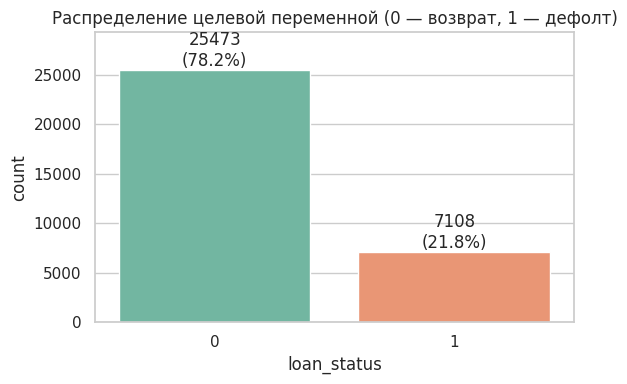

In [2]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=TARGET, hue=TARGET, data=df, palette="Set2", legend=False)
ax.set_title("Распределение целевой переменной (0 — возврат, 1 — дефолт)")

# Добавляем немного места сверху, чтобы текст не прилипал к заголовку
plt.ylim(0, df[TARGET].value_counts().max() * 1.15)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}\n({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

Подтверждается дисбаланс ~78/22. Модель, всегда предсказывающая 0, будет иметь accuracy 78%, но не выявит ни одного дефолта. Это главный аргумент в пользу метрик, ориентированных на положительный класс (дефолт): F1-score, Recall, ROC-AUC.

**3.3. Категориальные признаки: доля дефолтов по категориям**

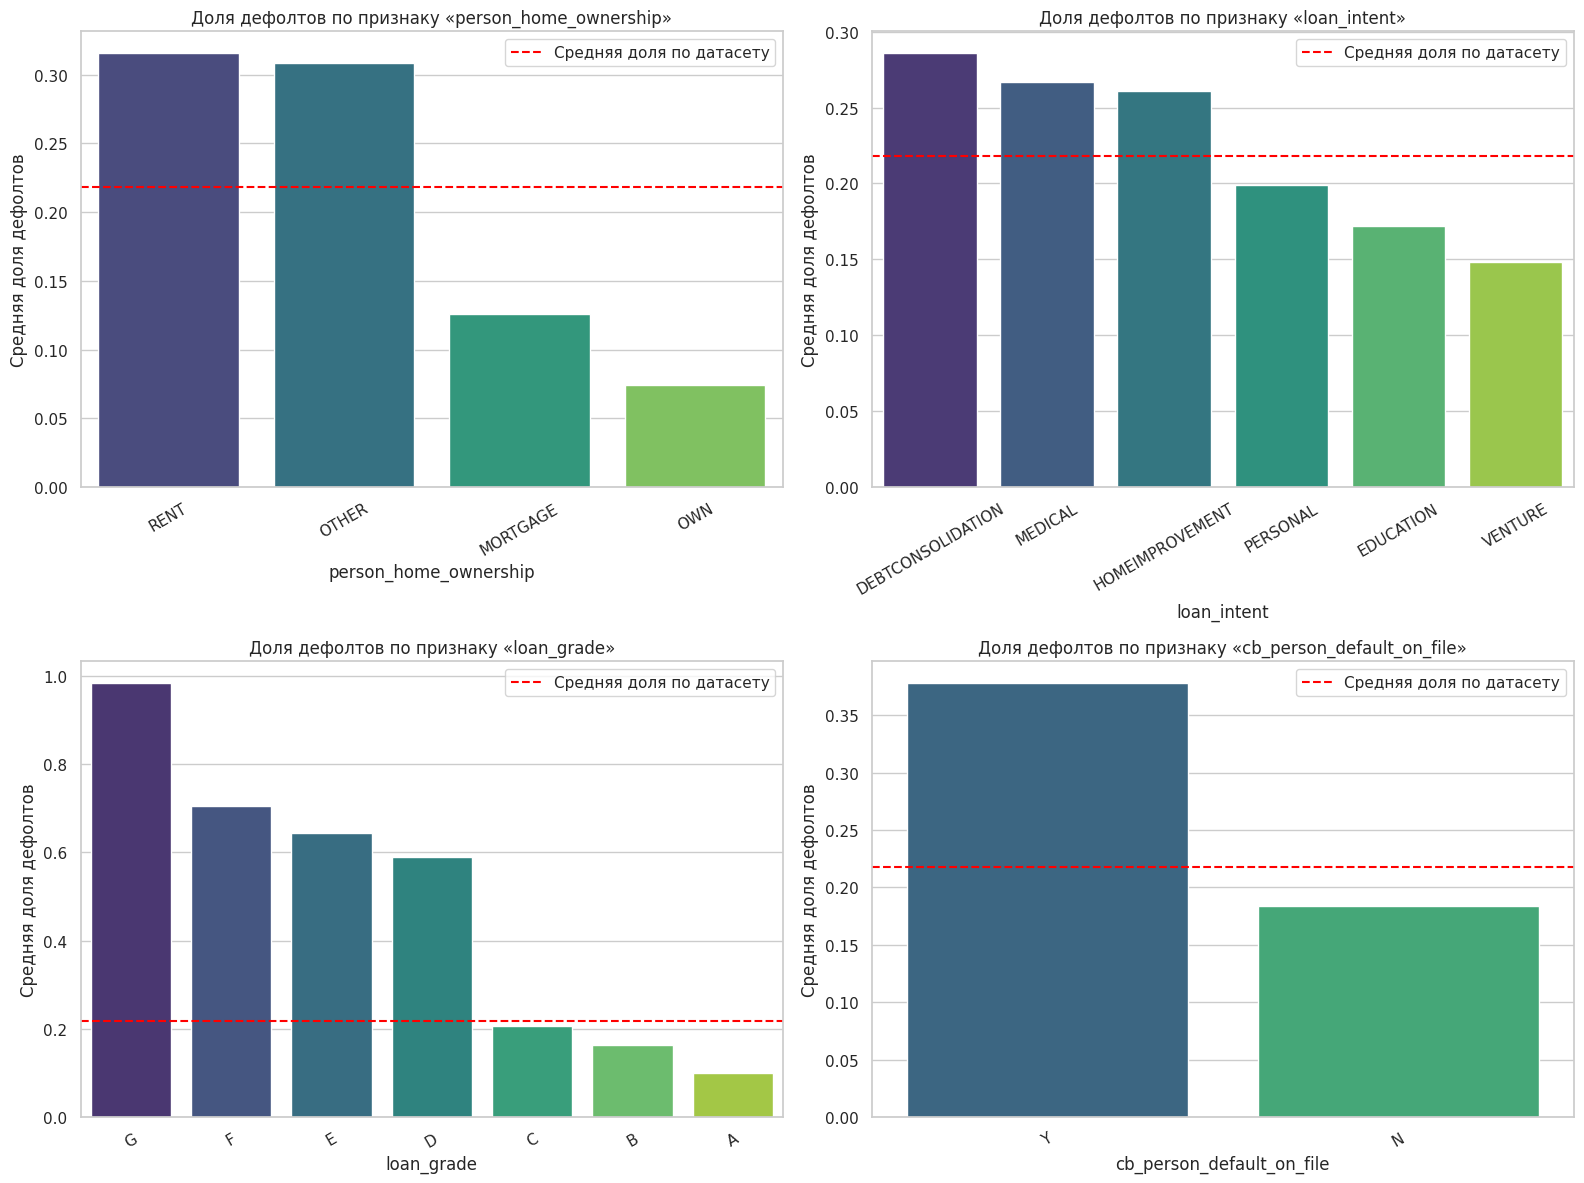

In [3]:
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # Считаем долю дефолтов в каждой категории
    default_rate = df.groupby(col)[TARGET].mean().sort_values(ascending=False).reset_index()
    sns.barplot(data=default_rate, x=col, y=TARGET, hue=col, palette="viridis", legend=False, ax=axes[i])
    axes[i].set_title(f"Доля дефолтов по признаку «{col}»")
    axes[i].set_ylabel("Средняя доля дефолтов")
    axes[i].axhline(df[TARGET].mean(), ls="--", color="red", label="Средняя доля по датасету")
    axes[i].legend()
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Пунктирная красная линия везде** — это средняя доля дефолтов по всему датасету (21.8%). Всё, что выше линии — риск выше среднего, ниже — риск ниже.

**•	График 1 (person_home_ownership - владение жильем):**
Вывод: Клиенты, которые снимают жилье (RENT) или находятся в категории OTHER, дефолтят чаще всего (31%). А вот те, кто владеет жильем (OWN), почти не допускают дефолтов (~7%). Это логично: наличие собственности говорит о финансовой стабильности.

**•	График 2 (loan_intent - цель кредита):**
Вывод: Наиболее рискованные кредиты — на рефинансирование/погашение долгов (DEBTCONSOLIDATION) и медицину (MEDICAL). Это значит, у людей уже есть финансовые проблемы. А вот кредиты на образование (EDUCATION) и развитие бизнеса (VENTURE) показывают риск ниже среднего.

**•	График 3 (loan_grade - кредитный рейтинг):**
Вывод: Идеальная закономерность. От грейда A (самый надежный, доля дефолтов ~6%) до грейда G (почти 100% дефолтов). Банк изначально присваивает грейд на основе своих внутренних рисков, поэтому этот признак будет невероятно важен для модели.

**•	График 4 (cb_person_default_on_file - история дефолтов в кредитной истории):**
Вывод: Если у человека был дефолт в прошлом (Y), то вероятность текущего дефолта у него огромна (выше 35%, столбик уходит далеко вверх). Если не было (N) — ниже среднего (около 18%). Прошлое поведение — лучший предиктор будущего.


**3.4. Корреляционная матрица (числовые признаки + target)**

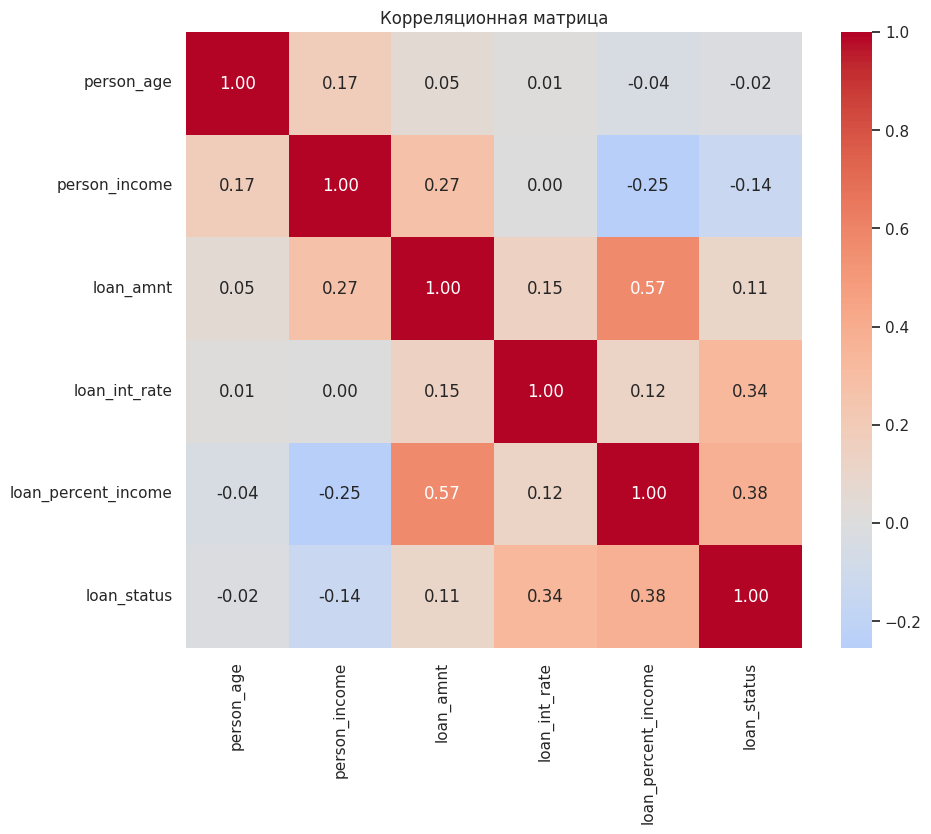

In [5]:
num_cols = ["person_age", "person_income", "loan_amnt", "loan_int_rate", "loan_percent_income"]
corr_cols = num_cols + [TARGET]
plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Корреляционная матрица")
plt.show()

**1. Связь признаков с целевой переменной (loan_status)**

Смотрим на самый правый столбец (или самую нижнюю строку):

•	loan_percent_income (0.38) и loan_int_rate (0.34): Это самые сильные числовые признаки. Связь положительная: чем выше процентная ставка по кредиту и чем выше долговая нагрузка (процент от дохода), тем выше вероятность дефолта. Это логично.

•	person_income (-0.14): Связь слабая, но обратная. Чем выше доход человека, тем реже он уходит в дефолт.

•	person_age (-0.02) и loan_amnt (0.11): Возраст вообще никак не связан с дефолтом (почти 0). Сумма кредита имеет очень слабую связь.

**2. Мультиколлинеарность (связь признаков между собой)**

Смотрим на пересечения числовых признаков вне последней строки/столбца:

•	loan_amnt и loan_percent_income (0.57): Очень заметная прямая связь. Логика: чем больше человек берет в абсолютных цифрах (сумма кредита), тем больше это бьет по его бюджету (процент от дохода).

•	person_income и loan_percent_income (-0.25): Обратная связь. Чем выше доход, тем меньшую долю от него составляет кредит.

•	person_income и loan_amnt (0.27): Люди с большим доходом берут чуть большие суммы кредитов.